In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

In [2]:
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_and = np.array([0, 0, 0, 1])
y_xor = np.array([0, 1, 1, 0])

In [3]:
data = pd.DataFrame(X, columns=["x1", "x2"])

data["AND"] = y_and
data["XOR"] = y_xor

data

,x1,x2,AND,XOR
0,0,0,0,0
1,0,1,0,1
2,1,0,0,1
3,1,1,1,0


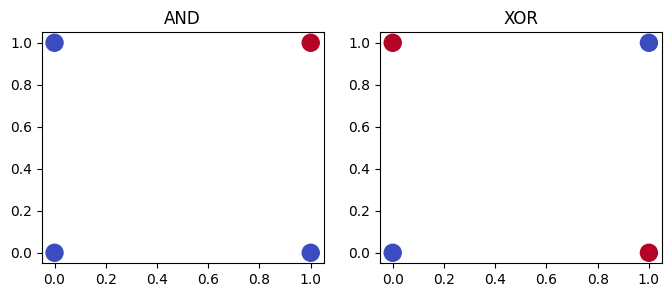

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

axes[0].scatter(
    X[:, 0], X[:, 1],
    c=y_and,
    cmap="coolwarm",
    s=150
)
axes[0].set_title("AND")

axes[1].scatter(
    X[:, 0], X[:, 1],
    c=y_xor,
    cmap="coolwarm",
    s=150
)
axes[1].set_title("XOR")

plt.show()

In [5]:
model_and = Perceptron(random_state=0)

model_and.fit(X, y_and)

pred_and = model_and.predict(X)

print("정답:", y_and)
print("예측:", pred_and)
print("정확도:", accuracy_score(y_and, pred_and))

정답: [0 0 0 1]
예측: [0 0 0 1]
정확도: 1.0


In [6]:
model_xor = Perceptron(random_state=0)

model_xor.fit(X, y_xor)

pred_xor = model_xor.predict(X)

print("정답:", y_xor)
print("예측:", pred_xor)
print("정확도:", accuracy_score(y_xor, pred_xor))

정답: [0 1 1 0]
예측: [0 0 0 0]
정확도: 0.5


In [7]:
result = pd.DataFrame(X, columns=["x1", "x2"])

result["AND 정답"] = y_and
result["AND 예측"] = pred_and
result["XOR 정답"] = y_xor
result["XOR 예측"] = pred_xor

result

,x1,x2,AND 정답,AND 예측,XOR 정답,XOR 예측
0,0,0,0,0,0,0
1,0,1,0,0,1,0
2,1,0,0,0,1,0
3,1,1,1,1,0,0


In [8]:
print("AND 정확도:", accuracy_score(y_and, pred_and))
print("XOR 정확도:", accuracy_score(y_xor, pred_xor))

AND 정확도: 1.0
XOR 정확도: 0.5


In [9]:
model_mlp = MLPClassifier(
    hidden_layer_sizes=(4,),
    activation="relu",
    solver="lbfgs",
    max_iter=2000,
    random_state=0
)

model_mlp.fit(X, y_xor)

pred_mlp = model_mlp.predict(X)

print("정답:", y_xor)
print("예측:", pred_mlp)
print("정확도:", accuracy_score(y_xor, pred_mlp))

정답: [0 1 1 0]
예측: [0 1 1 0]
정확도: 1.0


In [10]:
comparison = pd.DataFrame(X, columns=["x1", "x2"])

comparison["정답"] = y_xor
comparison["퍼셉트론"] = pred_xor
comparison["MLP"] = pred_mlp

comparison

,x1,x2,정답,퍼셉트론,MLP
0,0,0,0,0,0
1,0,1,1,0,1
2,1,0,1,0,1
3,1,1,0,0,0


In [11]:
print(
    "단일 퍼셉트론 정확도:",
    accuracy_score(y_xor, pred_xor)
)

print(
    "MLP 정확도:",
    accuracy_score(y_xor, pred_mlp)
)

단일 퍼셉트론 정확도: 0.5
MLP 정확도: 1.0


In [13]:
z = np.array([-2, -1, 0, 1, 2])

relu_z = np.maximum(0, z)

print("입력:", z)
print("ReLU 출력:", relu_z)

입력: [-2 -1  0  1  2]
ReLU 출력: [0 0 0 1 2]


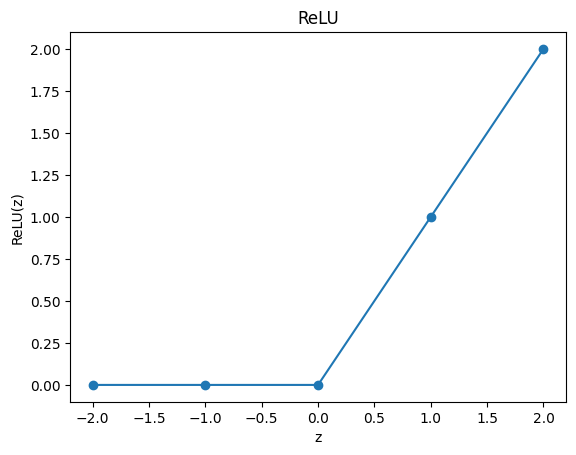

In [14]:
plt.plot(z, relu_z, marker="o")
plt.xlabel("z")
plt.ylabel("ReLU(z)")
plt.title("ReLU")
plt.show()

In [15]:
X_forward = np.array([
    [0, 1],
    [1, 0]
])

W1 = np.array([
    [0.5, 1.0],
    [1.0, 0.5]
])

b1 = np.array([0.1, 0.1])

In [16]:
print("X의 shape:", X_forward.shape)
print("W1의 shape:", W1.shape)

X의 shape: (2, 2)
W1의 shape: (2, 2)


In [17]:
Z1 = X_forward @ W1 + b1

print(Z1)
print("Z1의 shape:", Z1.shape)

[[1.1 0.6]
 [0.6 1.1]]
Z1의 shape: (2, 2)


In [18]:
A1 = np.maximum(0, Z1)

print(A1)
print("A1의 shape:", A1.shape)

[[1.1 0.6]
 [0.6 1.1]]
A1의 shape: (2, 2)


In [19]:
W2 = np.array([
    [1.0],
    [-1.0]
])

b2 = np.array([0.0])

In [20]:
Z2 = A1 @ W2 + b2

print(Z2)
print("Z2의 shape:", Z2.shape)

[[ 0.5]
 [-0.5]]
Z2의 shape: (2, 1)
